Import libraries

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")

Configuration

In [2]:
DATA_PATH = "data/processed/paddy_cleaned.csv"

OUTPUT_DIR = "experiments/random_forest"

os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Production 000 Mt."

FEATURES = [
    "Year",
    "production_lag_1",
    "production_lag_2",
    "production_lag_3",
    "rolling_mean_3",
    "rolling_std_3"
]

# Random Forest configuration
N_ESTIMATORS = 300
MAX_DEPTH = 5
MIN_SAMPLES_SPLIT = 4
MIN_SAMPLES_LEAF = 2
RANDOM_STATE = 42

# Train-test split
TRAIN_RATIO = 0.8

# Future forecast period
FORECAST_STEPS = 10

print("Random Forest Configuration")
print("Estimators:", N_ESTIMATORS)
print("Maximum depth:", MAX_DEPTH)
print("Training ratio:", TRAIN_RATIO)

Random Forest Configuration
Estimators: 300
Maximum depth: 5
Training ratio: 0.8


Load dataset

In [3]:
print("Loading prepared dataset...")

df = pd.read_csv(DATA_PATH)

df = df.sort_values("Year").reset_index(drop=True)

print("Dataset loaded successfully!")

print("Total records:", len(df))

display(df.head())

Loading prepared dataset...
Dataset loaded successfully!
Total records: 61


,Year,Production 000 Mt.
0,1952,604
1,1953,458
2,1954,650
3,1955,747
4,1956,574


Generate lag features

In [4]:
# Previous production values
df["production_lag_1"] = df[TARGET].shift(1)

df["production_lag_2"] = df[TARGET].shift(2)

df["production_lag_3"] = df[TARGET].shift(3)

# Rolling features using previous years only
df["rolling_mean_3"] = (
    df[TARGET].shift(1).rolling(3).mean()
)

df["rolling_std_3"] = (
    df[TARGET].shift(1).rolling(3).std()
)

# Remove records with missing lag values
df = df.dropna().reset_index(drop=True)

print("Feature engineering completed!")

print("Total samples:", len(df))

print("\nGenerated features:")
print(FEATURES)

display(df.head())

Feature engineering completed!
Total samples: 58

Generated features:
['Year', 'production_lag_1', 'production_lag_2', 'production_lag_3', 'rolling_mean_3', 'rolling_std_3']


,Year,Production 000 Mt.,production_lag_1,production_lag_2,production_lag_3,rolling_mean_3,rolling_std_3
0,1955,747,650.0,458.0,604.0,570.666667,100.246363
1,1956,574,747.0,650.0,458.0,618.333333,147.079344
2,1957,654,574.0,747.0,650.0,657.000000,86.712168
3,1958,765,654.0,574.0,747.0,658.333333,86.581368
4,1959,761,765.0,654.0,574.0,664.333333,95.918368


Prepare feature and target

In [5]:
X = df[FEATURES]

y = df[TARGET]

print("Feature dataset shape:", X.shape)

print("Target dataset shape:", y.shape)

Feature dataset shape: (58, 6)
Target dataset shape: (58,)


Chronological train-test split

In [6]:
split_index = int(
    len(df) * TRAIN_RATIO
)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))

print("Testing samples:", len(X_test))

print(
    "\nTraining period:",
    df["Year"].iloc[0],
    "-",
    df["Year"].iloc[split_index - 1]
)

print(
    "Testing period:",
    df["Year"].iloc[split_index],
    "-",
    df["Year"].iloc[-1]
)

Training samples: 46
Testing samples: 12

Training period: 1955 - 2000
Testing period: 2001 - 2012


Train Random Forest model

In [7]:
print("Training Random Forest model...")

rf_model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    max_features=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest model...
Random Forest training completed!


Perform walk forward validation

In [8]:
print("Performing walk-forward validation...")

# Initial historical training data
history = df.iloc[:split_index].copy()

walk_forward_predictions = []

walk_forward_actuals = []

walk_forward_years = []

for i in range(split_index, len(df)):

    current_year = int(df.loc[i, "Year"])

    # Historical production values
    values = history[TARGET].tolist()

    # Generate current-year features
    features = pd.DataFrame([{
        "Year": current_year,
        "production_lag_1": values[-1],
        "production_lag_2": values[-2],
        "production_lag_3": values[-3],
        "rolling_mean_3": np.mean(values[-3:]),
        "rolling_std_3": np.std(values[-3:], ddof=1)
    }])

    # Predict current year
    prediction = rf_model.predict(
        features[FEATURES]
    )[0]

    actual = df.loc[i, TARGET]

    walk_forward_predictions.append(prediction)

    walk_forward_actuals.append(actual)

    walk_forward_years.append(current_year)

    # Add actual production to historical data
    history = pd.concat([
        history,
        df.iloc[[i]]
    ], ignore_index=True)

print("Walk-forward validation completed!")

print("Predictions generated:", len(walk_forward_predictions))

Performing walk-forward validation...
Walk-forward validation completed!
Predictions generated: 12


Evaluate Random forest model

In [9]:
mae = mean_absolute_error(
    walk_forward_actuals,
    walk_forward_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        walk_forward_actuals,
        walk_forward_predictions
    )
)

mape = np.mean(
    np.abs(
        (
            np.array(walk_forward_actuals)
            - np.array(walk_forward_predictions)
        )
        / np.array(walk_forward_actuals)
    )
) * 100

print("========== RANDOM FOREST EVALUATION ==========")

print(f"MAE:  {mae:.2f}")

print(f"RMSE: {rmse:.2f}")

print(f"MAPE: {mape:.2f}%")

========== RANDOM FOREST EVALUATION ==========
MAE:  858.15
RMSE: 991.21
MAPE: 23.74%


Save walk-forward predictions

In [10]:
results = pd.DataFrame({
    "Year": walk_forward_years,
    "Actual Production": walk_forward_actuals,
    "Predicted Production": walk_forward_predictions
})

results.to_csv(
    f"{OUTPUT_DIR}/random_forest_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

display(results)

Predictions saved successfully!


,Year,Actual Production,Predicted Production
0,2001,2695,2480.591376
1,2002,2860,2480.591376
2,2003,3067,2480.591376
3,2004,2628,2518.620098
4,2005,3246,2491.388526
5,2006,3341,2567.730392
6,2007,3131,2547.399225
7,2008,3875,2480.591376
8,2009,3652,2547.399225
9,2010,4301,2547.399225


Calculate fetaure importance

In [11]:
importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("========== FEATURE IMPORTANCE ==========")

display(importance)

========== FEATURE IMPORTANCE ==========


,Feature,Importance
0,Year,0.454029
1,production_lag_1,0.344646
2,production_lag_2,0.084619
4,rolling_mean_3,0.076651
3,production_lag_3,0.031103
5,rolling_std_3,0.008953


Visualize feature importance

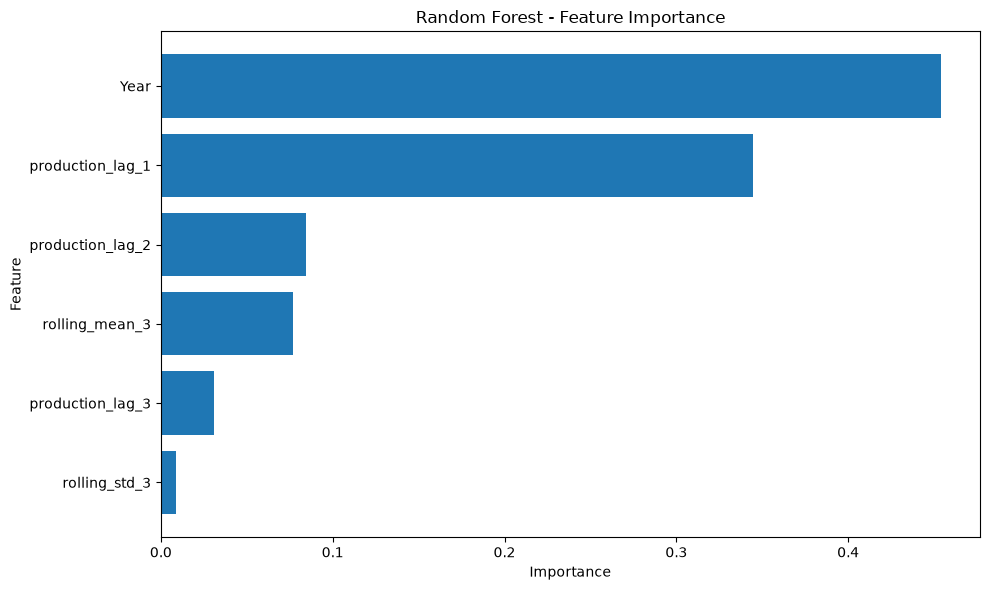

In [12]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Random Forest - Feature Importance")

plt.xlabel("Importance")

plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/random_forest_feature_importance.png",
    dpi=300
)

plt.show()

Save feature importance

In [13]:
importance.to_csv(
    f"{OUTPUT_DIR}/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


Actual vs. predicted visualization

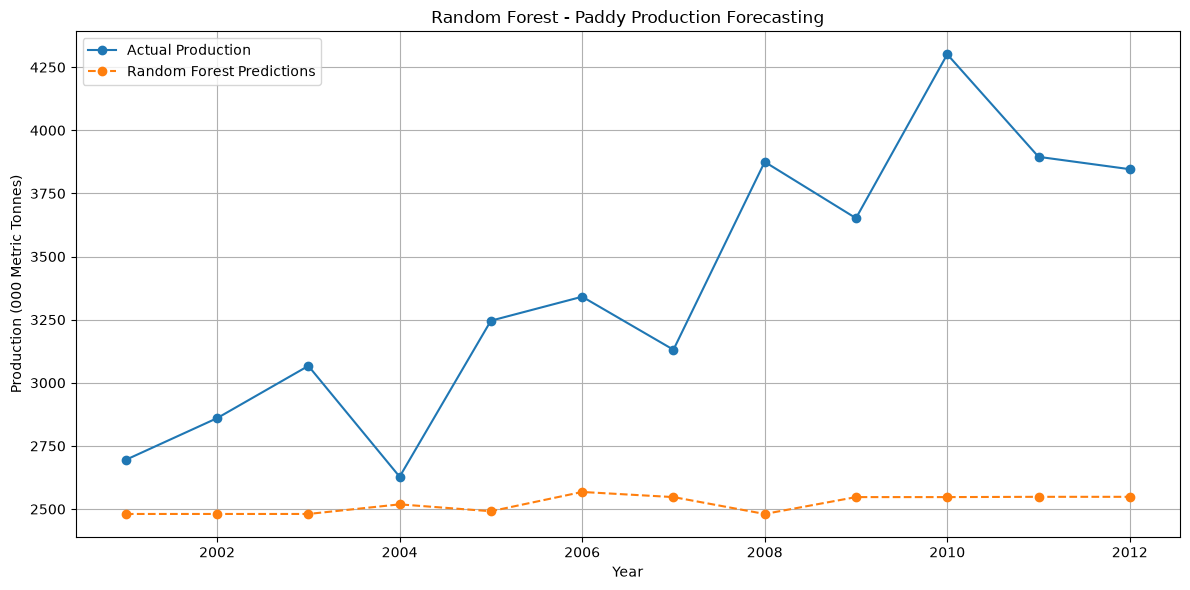

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    walk_forward_years,
    walk_forward_actuals,
    marker="o",
    label="Actual Production"
)

plt.plot(
    walk_forward_years,
    walk_forward_predictions,
    marker="o",
    linestyle="--",
    label="Random Forest Predictions"
)

plt.title("Random Forest - Paddy Production Forecasting")

plt.xlabel("Year")

plt.ylabel("Production (000 Metric Tonnes)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/random_forest_results.png",
    dpi=300
)

plt.show()

Train final model using all historical observations

In [15]:
print("Training final Random Forest model...")

final_model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    min_samples_split=MIN_SAMPLES_SPLIT,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    max_features=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

final_model.fit(X, y)

print("Final model training completed!")

Training final Random Forest model...
Final model training completed!


Forecast the next 10 years

In [16]:
print("========== FUTURE FORECAST ==========")

# Latest historical production values
future_history = df[TARGET].tolist()

future_forecasts = []

last_year = int(df["Year"].max())

for step in range(1, FORECAST_STEPS + 1):

    future_year = last_year + step

    future_features = pd.DataFrame([{
        "Year": future_year,
        "production_lag_1": future_history[-1],
        "production_lag_2": future_history[-2],
        "production_lag_3": future_history[-3],
        "rolling_mean_3": np.mean(future_history[-3:]),
        "rolling_std_3": np.std(
            future_history[-3:],
            ddof=1
        )
    }])

    prediction = final_model.predict(
        future_features[FEATURES]
    )[0]

    future_forecasts.append(prediction)

    # Add predicted production to history
    future_history.append(prediction)

future_results = pd.DataFrame({
    "Year": range(
        last_year + 1,
        last_year + FORECAST_STEPS + 1
    ),
    "Forecasted Production": future_forecasts
})

display(future_results)

========== FUTURE FORECAST ==========


,Year,Forecasted Production
0,2013,3875.698017
1,2014,3875.698017
2,2015,3875.698017
3,2016,3875.698017
4,2017,3875.698017
5,2018,3875.698017
6,2019,3875.698017
7,2020,3875.698017
8,2021,3875.698017
9,2022,3875.698017


Visualize future forecast

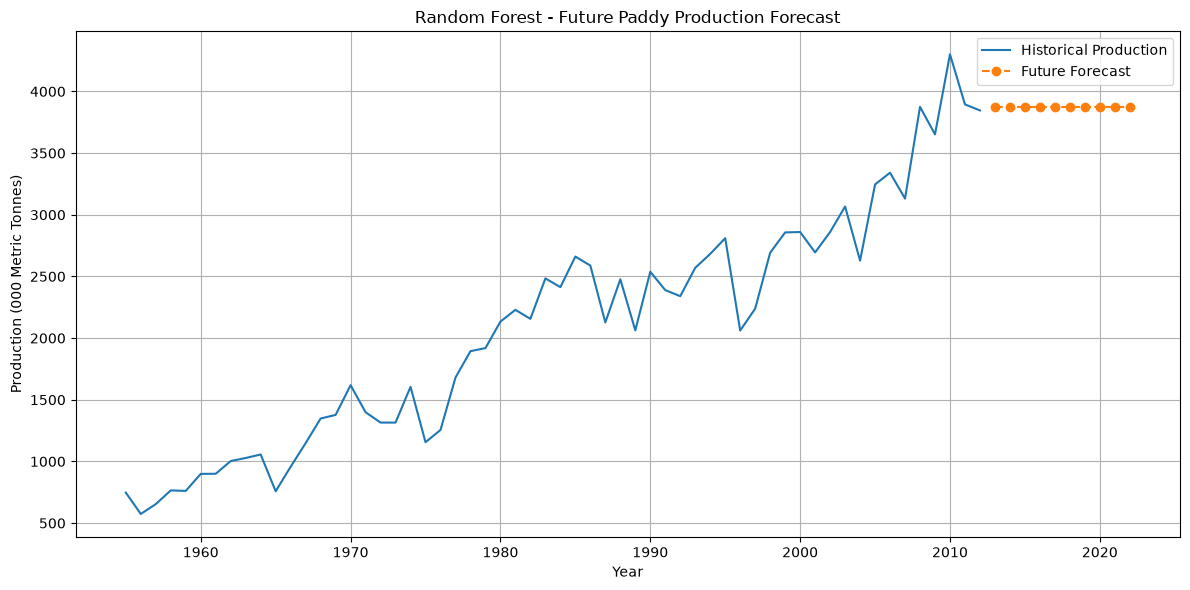

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["Year"],
    df[TARGET],
    label="Historical Production"
)

plt.plot(
    future_results["Year"],
    future_results["Forecasted Production"],
    label="Future Forecast",
    linestyle="--",
    marker="o"
)

plt.title("Random Forest - Future Paddy Production Forecast")

plt.xlabel("Year")

plt.ylabel("Production (000 Metric Tonnes)")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/random_forest_future_forecast.png",
    dpi=300
)

plt.show()

Save future forecast

In [18]:
future_results.to_csv(
    f"{OUTPUT_DIR}/random_forest_future_forecast.csv",
    index=False
)

print("Future forecast saved successfully!")

Future forecast saved successfully!


Final summary

In [19]:
print("========== RANDOM FOREST SUMMARY ==========")

print("Model: Random Forest Regressor")

print("Training samples:", len(X_train))

print("Testing samples:", len(X_test))

print(f"MAE:  {mae:.2f}")

print(f"RMSE: {rmse:.2f}")

print(f"MAPE: {mape:.2f}%")

print("\nGenerated files:")

print(f"1. {OUTPUT_DIR}/random_forest_predictions.csv")

print(f"2. {OUTPUT_DIR}/feature_importance.csv")

print(f"3. {OUTPUT_DIR}/random_forest_feature_importance.png")

print(f"4. {OUTPUT_DIR}/random_forest_results.png")

print(f"5. {OUTPUT_DIR}/random_forest_future_forecast.csv")

print(f"6. {OUTPUT_DIR}/random_forest_future_forecast.png")

print("\nRandom Forest experiment completed!")

========== RANDOM FOREST SUMMARY ==========
Model: Random Forest Regressor
Training samples: 46
Testing samples: 12
MAE:  858.15
RMSE: 991.21
MAPE: 23.74%

Generated files:
1. experiments/random_forest/random_forest_predictions.csv
2. experiments/random_forest/feature_importance.csv
3. experiments/random_forest/random_forest_feature_importance.png
4. experiments/random_forest/random_forest_results.png
5. experiments/random_forest/random_forest_future_forecast.csv
6. experiments/random_forest/random_forest_future_forecast.png

Random Forest experiment completed!
